In [1]:
import os
import sys
import glob

import joblib
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.helper_functions import normalize_series
from utils.plotting import plot_movement_data
from utils.constants import Configs
from utils.loso_models.zscore_detector import ZScoreDetector
from utils.loso_models.dbscan_detector import DBSCANDetector
from utils.loso_models.iforest_detector import IForestDetector
from utils.loso_models.lof_detector import LOFDetector
from utils.loso_models.ocsvm_detector import OCSVMDetector

RESULTS_DIR = Configs._wrist_only_loso_results_cache_dir
TARGET_MOVEMENT = "Pick"
MODEL = "DBSCAN"

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


## Import Data

In [2]:
# Load the processed data from the csv
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [3]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID'])
total_known_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
outliers_csv.head()

Total known outliers: 14


,sub,repID
0,2,2
1,4,1
2,5,2
3,5,5
4,7,1


In [4]:
# HELPER FUNCTIONS 

def load_features(target_movement):
    """
    Used for feature extraction besed models.
    Gets Feature Extraction features for the given target movement from the cache.
    """

    cache_path = Configs.wrist_only_feature_extraction_features(target_movement)
    if not os.path.exists(cache_path):
        raise FileNotFoundError(f"Features for {target_movement} not found at {cache_path}. Please run the feature extraction notebook first.")

    features_df = joblib.load(cache_path)
    features_df = features_df.sort_values(by=['sub', 'repID', 'movID']).reset_index(drop=True)

    return features_df

def load_DTW_matrix(target_movement):
    cache_path = Configs.wrist_only_constrained_dtw_distance_matrix(target_movement)
    if not os.path.exists(cache_path):
        raise FileNotFoundError(f"DTW distance matrix for {target_movement} not found at {cache_path}. Please run the DTW calculation notebook first.")   

    return joblib.load(cache_path)

def load_raw_dataset():
    """"
    Load the processed data from the csv
    """
    cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
    if not os.path.exists(cache_path):
        raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

    return pd.read_csv(cache_path)

def scale_feaures(features_df):
    from sklearn.preprocessing import StandardScaler
    """
    Scales the features in the given DataFrame and returns the scaled features as a numpy array.
    """
    COLS_TO_TRAIN = Configs.FEATURE_EXTRACTION_COLS_TO_TRAIN
    X_features_raw = features_df[COLS_TO_TRAIN].values
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(X_features_raw)
    return scaled_features

def train_model_and_predict(model_name, hyperparameters, features, paradigm="FeatureBased"):
    metric_type = None
    if paradigm == "ShapeBased":
        metric_type = "precomputed"
    elif paradigm == "FeatureBased":
        metric_type = "euclidean"

    detector_class = get_detector_class_from_model_name(model_name)
    if detector_class is None:
        raise ValueError(f"Model {model_name} not found.")

    detector = detector_class(**hyperparameters, metric_type=metric_type)
    labels = detector.fit_predict(features)
    return labels

def get_detector_class_from_model_name(model_name):
    model_dict = {
        'DBSCAN': DBSCANDetector,
        'ZScore': ZScoreDetector,
        'IForest': IForestDetector,
        'LOF': LOFDetector,
        'OCSVM': OCSVMDetector,
    }
    return model_dict.get(model_name, None)
    

def get_movement_from_path(model_path):
    # Extract model name from path
    file_name = os.path.basename(model_path).split('.')[0]
    file_name_array = file_name.split('_')
    for key in ['Pick', 'Move', 'Place']:
        if key in file_name_array:
            return key
    return 'Unknown Movement'

def load_all_fold_results(results_dir):
    rows = []

    for file in glob.glob(os.path.join(results_dir, "*.pkl")):
        obj = joblib.load(file)

        if isinstance(obj, dict) and "Fold_History" in obj:
            df = pd.DataFrame(obj["Fold_History"])

            # Recover metadata from the filename:
            # wrist_only_loso_results_{model}_{representation}_{movement}.pkl
            stem = Path(file).stem.replace("wrist_only_loso_results_", "")
            model, representation, phase = stem.rsplit("_", 2)

            df["Model"] = model
            df["Representation"] = representation
            df["Phase"] = phase
            rows.append(df)

        elif isinstance(obj, pd.DataFrame):
            rows.append(obj)

        else:
            raise TypeError(f"{file} contains {type(obj).__name__}, not a supported result format")

    return pd.concat(rows, ignore_index=True)

def get_best_hyperparameters_from_fold_history(df):
    """
        Determines the most frequently selected hyperparameters across all folds.
    """
    if df is None or df.empty:
        print("⚠️ WARNING: No valid model was found in any fold! Returning the first config from the grid.")
        return {}

    param_counts = {}
    for _, row in df.iterrows():
        param_tuple = tuple(sorted(row['params'].items()))
        param_counts[param_tuple] = param_counts.get(param_tuple, 0) + 1

    best_overall_tuple = max(param_counts, key=param_counts.get)
    return dict(best_overall_tuple)

## Plot Feature Extraction Morphology vs Acceleration

In [5]:
loso_results_df = load_all_fold_results(RESULTS_DIR)
features_df = load_features(TARGET_MOVEMENT)
scaled_features = scale_feaures(features_df)

In [6]:
model_loso_results_df = loso_results_df.iloc[(loso_results_df['Representation'] == 'FeatureBased') & (loso_results_df['Model'] == MODEL)]
best_params = get_best_hyperparameters_from_fold_history(model_loso_results_df)

In [7]:
features_df['anomaly'] = train_model_and_predict(MODEL, best_params, scaled_features, paradigm="FeatureBased")
outliers_details = features_df[features_df['anomaly'] == -1][['sub', 'repID', 'movID']]

In [8]:
cols_to_extract = ['sub', 'repID', 'movID']
outliers_metadata_df = features_df.loc[outliers_details.index, cols_to_extract].copy()
print("Quem são os outliers reais?")
print(outliers_metadata_df)

Quem são os outliers reais?
     sub  repID  movID
1      1      1      3
24     2      2      1
86     5      2      5
140    8      1      1
161    9      1      3
190   10      3      5
200   11      1      1
202   11      1      5
220   12      1      1
222   12      1      5
223   12      1      7
241   13      1      3
245   13      2      3
254   13      4      5
298   15      5      5
301   16      1      3
302   16      1      5
314   16      4      5
318   16      5      5
341   18      1      3
345   18      2      3
366   19      2      5


In [9]:
ground_truth_trials = set(zip(outliers_csv['sub'], outliers_csv['repID']))
predicted_trials = set(zip(outliers_metadata_df['sub'], outliers_metadata_df['repID']))

all_mov_trials = df[df['movLabel'] == TARGET_MOVEMENT][['sub', 'repID']].drop_duplicates()
all_mov_trials_set = set(zip(all_mov_trials['sub'], all_mov_trials['repID']))

tp_set = ground_truth_trials.intersection(predicted_trials)
fp_set = predicted_trials - ground_truth_trials
fn_set = ground_truth_trials - predicted_trials
tn_set = all_mov_trials_set - ground_truth_trials - predicted_trials

def get_target_movements(target_set, sample_size=1, is_fp=False):
    target_list = list(target_set)
    if not target_list:
        return pd.DataFrame()
        
    sampled = pd.DataFrame(target_list, columns=['sub', 'repID']).sample(n=min(sample_size, len(target_list)), random_state=42)
    
    extracted_data = []
    for _, row in sampled.iterrows():
        sub, rep = row['sub'], row['repID']
        trial_data = df[(df['sub'] == sub) & (df['repID'] == rep) & (df['movLabel'] == TARGET_MOVEMENT)]
        
        if is_fp:
            # Isolate only the exact movement that triggered the false alarm
            flagged_movs = outliers_metadata_df[(outliers_metadata_df['sub'] == sub) & (outliers_metadata_df['repID'] == rep)]['movID'].tolist()
            trial_data = trial_data[trial_data['movID'].isin(flagged_movs)]
            
        extracted_data.append(trial_data)
        
    return pd.concat(extracted_data)

tn_data = get_target_movements(tn_set)
fp_data = get_target_movements(fp_set, is_fp=True)
fn_data = get_target_movements(fn_set)

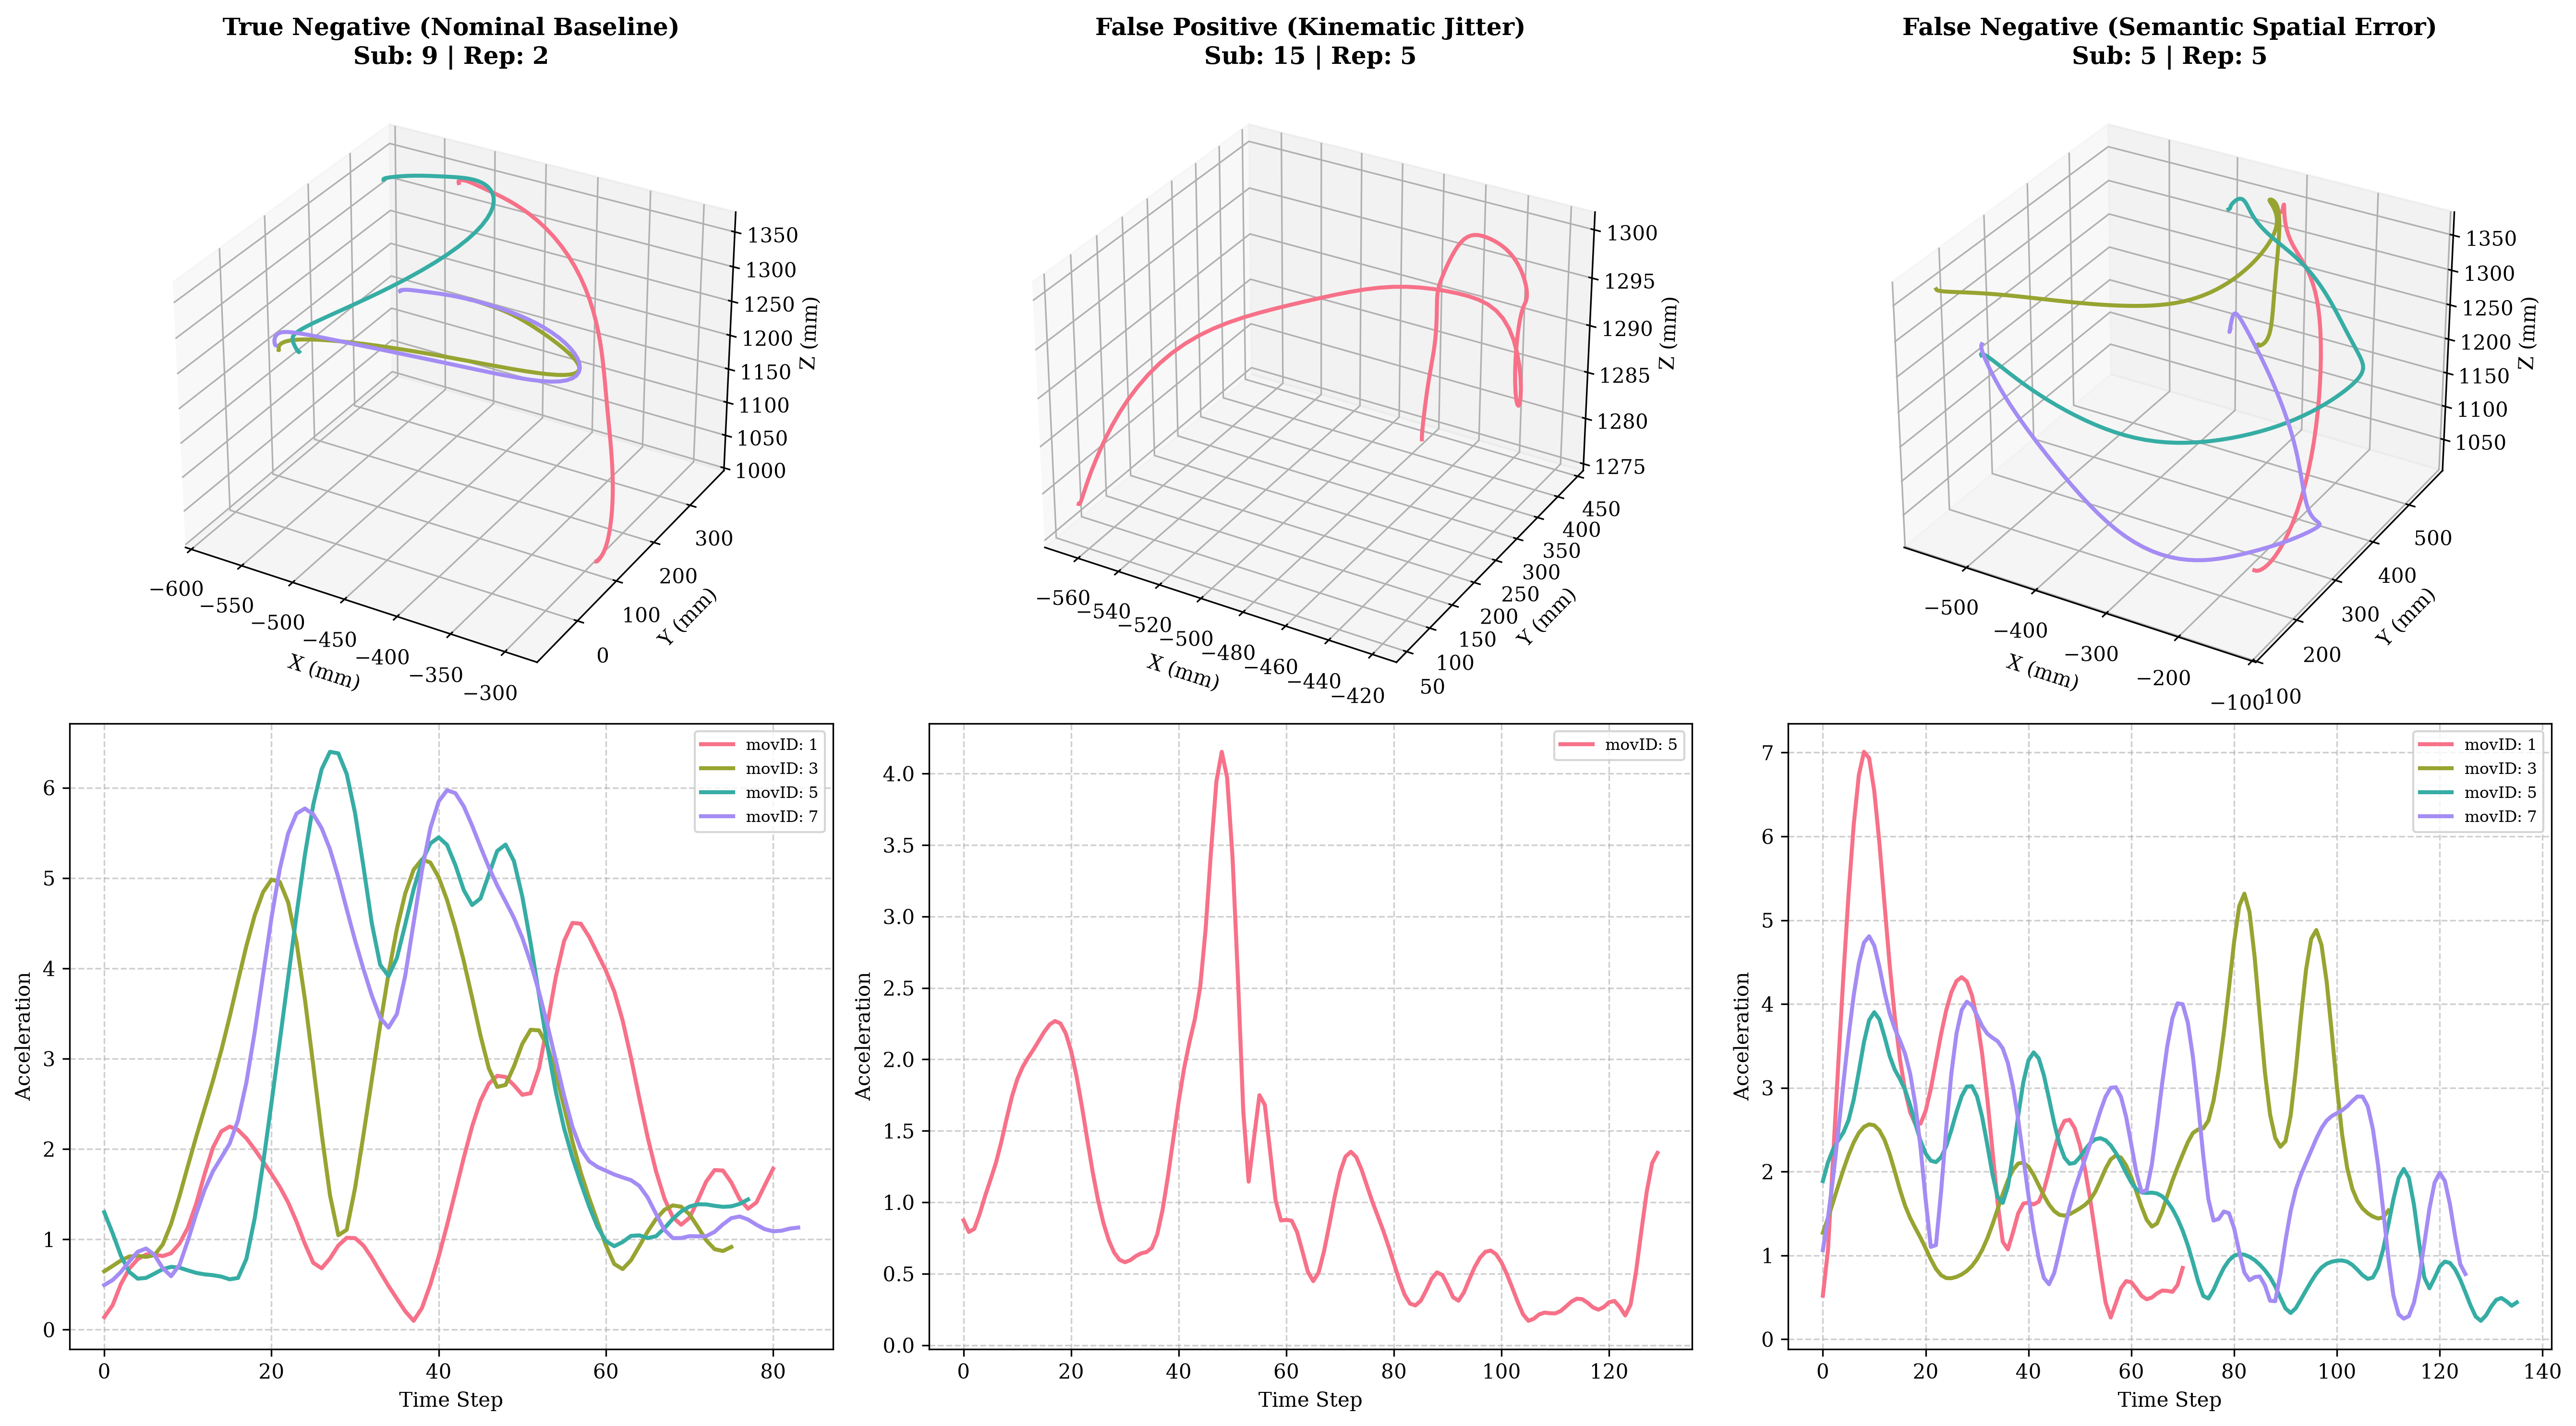

In [10]:
def plot_feature_biomechanics(tn_df, fp_df, fn_df, feature_col='acc', feature_label='Acceleration'):
    plt.rcParams.update({'font.size': 10, 'font.family': 'serif'})
    fig = plt.figure(figsize=(18, 10), dpi=300)
    
    datasets = [
        (tn_df, 1, 'True Negative (Nominal Baseline)'),
        (fp_df, 2, 'False Positive (Kinematic Jitter)'),
        (fn_df, 3, 'False Negative (Semantic Spatial Error)')
    ]
    
    for data, col_idx, title in datasets:
        if data.empty:
            continue
            
        sub_id = data['sub'].iloc[0]
        rep_id = data['repID'].iloc[0]
        unique_movs = data['movID'].unique()
        colors = sns.color_palette("husl", len(unique_movs))
        
        ax3d = fig.add_subplot(2, 3, col_idx, projection='3d')
        for mov_id, color in zip(unique_movs, colors):
            subset = data[data['movID'] == mov_id]
            ax3d.plot(subset['x'], subset['y'], subset['z'], color=color, linewidth=2)
        
        ax3d.set_title(f"{title}\nSub: {sub_id} | Rep: {rep_id}", fontweight='bold')
        ax3d.set_xlabel('X (mm)')
        ax3d.set_ylabel('Y (mm)')
        ax3d.set_zlabel('Z (mm)')
        
        ax1d = fig.add_subplot(2, 3, col_idx + 3)
        for mov_id, color in zip(unique_movs, colors):
            subset = data[data['movID'] == mov_id]
            ax1d.plot(range(len(subset)), subset[feature_col], color=color, linewidth=2, label=f'movID: {mov_id}')
            
        ax1d.set_xlabel('Time Step')
        ax1d.set_ylabel(f'{feature_label}')
        ax1d.grid(True, linestyle='--', alpha=0.6)
        ax1d.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

plot_feature_biomechanics(tn_data, fp_data, fn_data, feature_col='acc', feature_label='Acceleration')

## Plot DTW Morphology Plot 

In [11]:
loso_results_df = load_all_fold_results(RESULTS_DIR)
model_loso_results_df = loso_results_df.iloc[(loso_results_df['Representation'] == 'ShapeBased') & (loso_results_df['Model'] == MODEL)]
best_params = get_best_hyperparameters_from_fold_history(model_loso_results_df)

In [12]:
dtw_matrix = load_DTW_matrix("Pick")

# Making sure that the metadata is perfectly aligned with the movement data matrix (X_movement)
df = load_raw_dataset()
df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

group_array = ['x', 'y', 'z']
sample_size = None

# Usar o TimeSeriesScalerMeanVariance para normalizar as séries temporais,
# mas sem escalar para zero média e unidade de variância (useScaler=False)
X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series: 100%|██████████| 380/380 [00:00<00:00, 5133.89it/s]


Shape of first series: (111, 3)
Shape of formatted series: (380, 241, 3)


In [ ]:
labels = train_model_and_predict(MODEL, best_params, dtw_matrix, paradigm="ShapeBased")

outlier_indices = np.where(labels == -1)[0]

# Reconstruct metadata for cross-referencing with the original CSV
grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

In [ ]:
real_outliers_info = metadata_df.iloc[outlier_indices][["sub", "repID", "movID", "movLabel"]]
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

print("Real Outliers Metadata:")
print(real_outliers_info)

Quem são os outliers reais?
     sub  repID  movID movLabel
22     2      1      5     Pick
23     2      1      7     Pick
42     3      1      5     Pick
43     3      1      7     Pick
45     3      2      3     Pick
..   ...    ...    ...      ...
345   18      2      3     Pick
362   19      1      5     Pick
363   19      1      7     Pick
366   19      2      5     Pick
378   19      5      5     Pick

[84 rows x 4 columns]


In [15]:
ground_truth_trials = set(zip(outliers_csv['sub'], outliers_csv['repID']))
predicted_trials = set(zip(real_outliers_info['sub'], real_outliers_info['repID']))

all_target_trials = df[df['movLabel'] == TARGET_MOVEMENT][['sub', 'repID']].drop_duplicates()
all_trials_set = set(zip(all_target_trials['sub'], all_target_trials['repID']))

tn_set = all_trials_set - ground_truth_trials - predicted_trials
fp_set = predicted_trials - ground_truth_trials
fn_set = ground_truth_trials - predicted_trials

def extract_trial_data(target_set, raw_df, predictions=None, sample_size=1, is_fp=False):
    target_list = list(target_set)
    if not target_list:
        return pd.DataFrame()
        
    sampled = pd.DataFrame(target_list, columns=['sub', 'repID']).sample(n=min(sample_size, len(target_list)), random_state=42)
    
    extracted_data = []
    for _, row in sampled.iterrows():
        sub, rep = row['sub'], row['repID']
        trial_data = raw_df[(raw_df['sub'] == sub) & (raw_df['repID'] == rep) & (raw_df['movLabel'] == TARGET_MOVEMENT)]
        
        if is_fp and predictions is not None:
            flagged_movs = predictions[(predictions['sub'] == sub) & (predictions['repID'] == rep)]['movID'].tolist()
            trial_data = trial_data[trial_data['movID'].isin(flagged_movs)]
            
        extracted_data.append(trial_data)
        
    return pd.concat(extracted_data)

tn_dtw_data = extract_trial_data(tn_set, df)
fp_dtw_data = extract_trial_data(fp_set, df, predictions=real_outliers_info, is_fp=True)
fn_dtw_data = extract_trial_data(fn_set, df)

In [16]:
tn_dtw_data.groupby(['sub', 'repID', 'movID']).size().reset_index(name='count').sort_values(by='count', ascending=False)

,sub,repID,movID,count
2,10,1,5,162
1,10,1,3,128
3,10,1,7,112
0,10,1,1,82


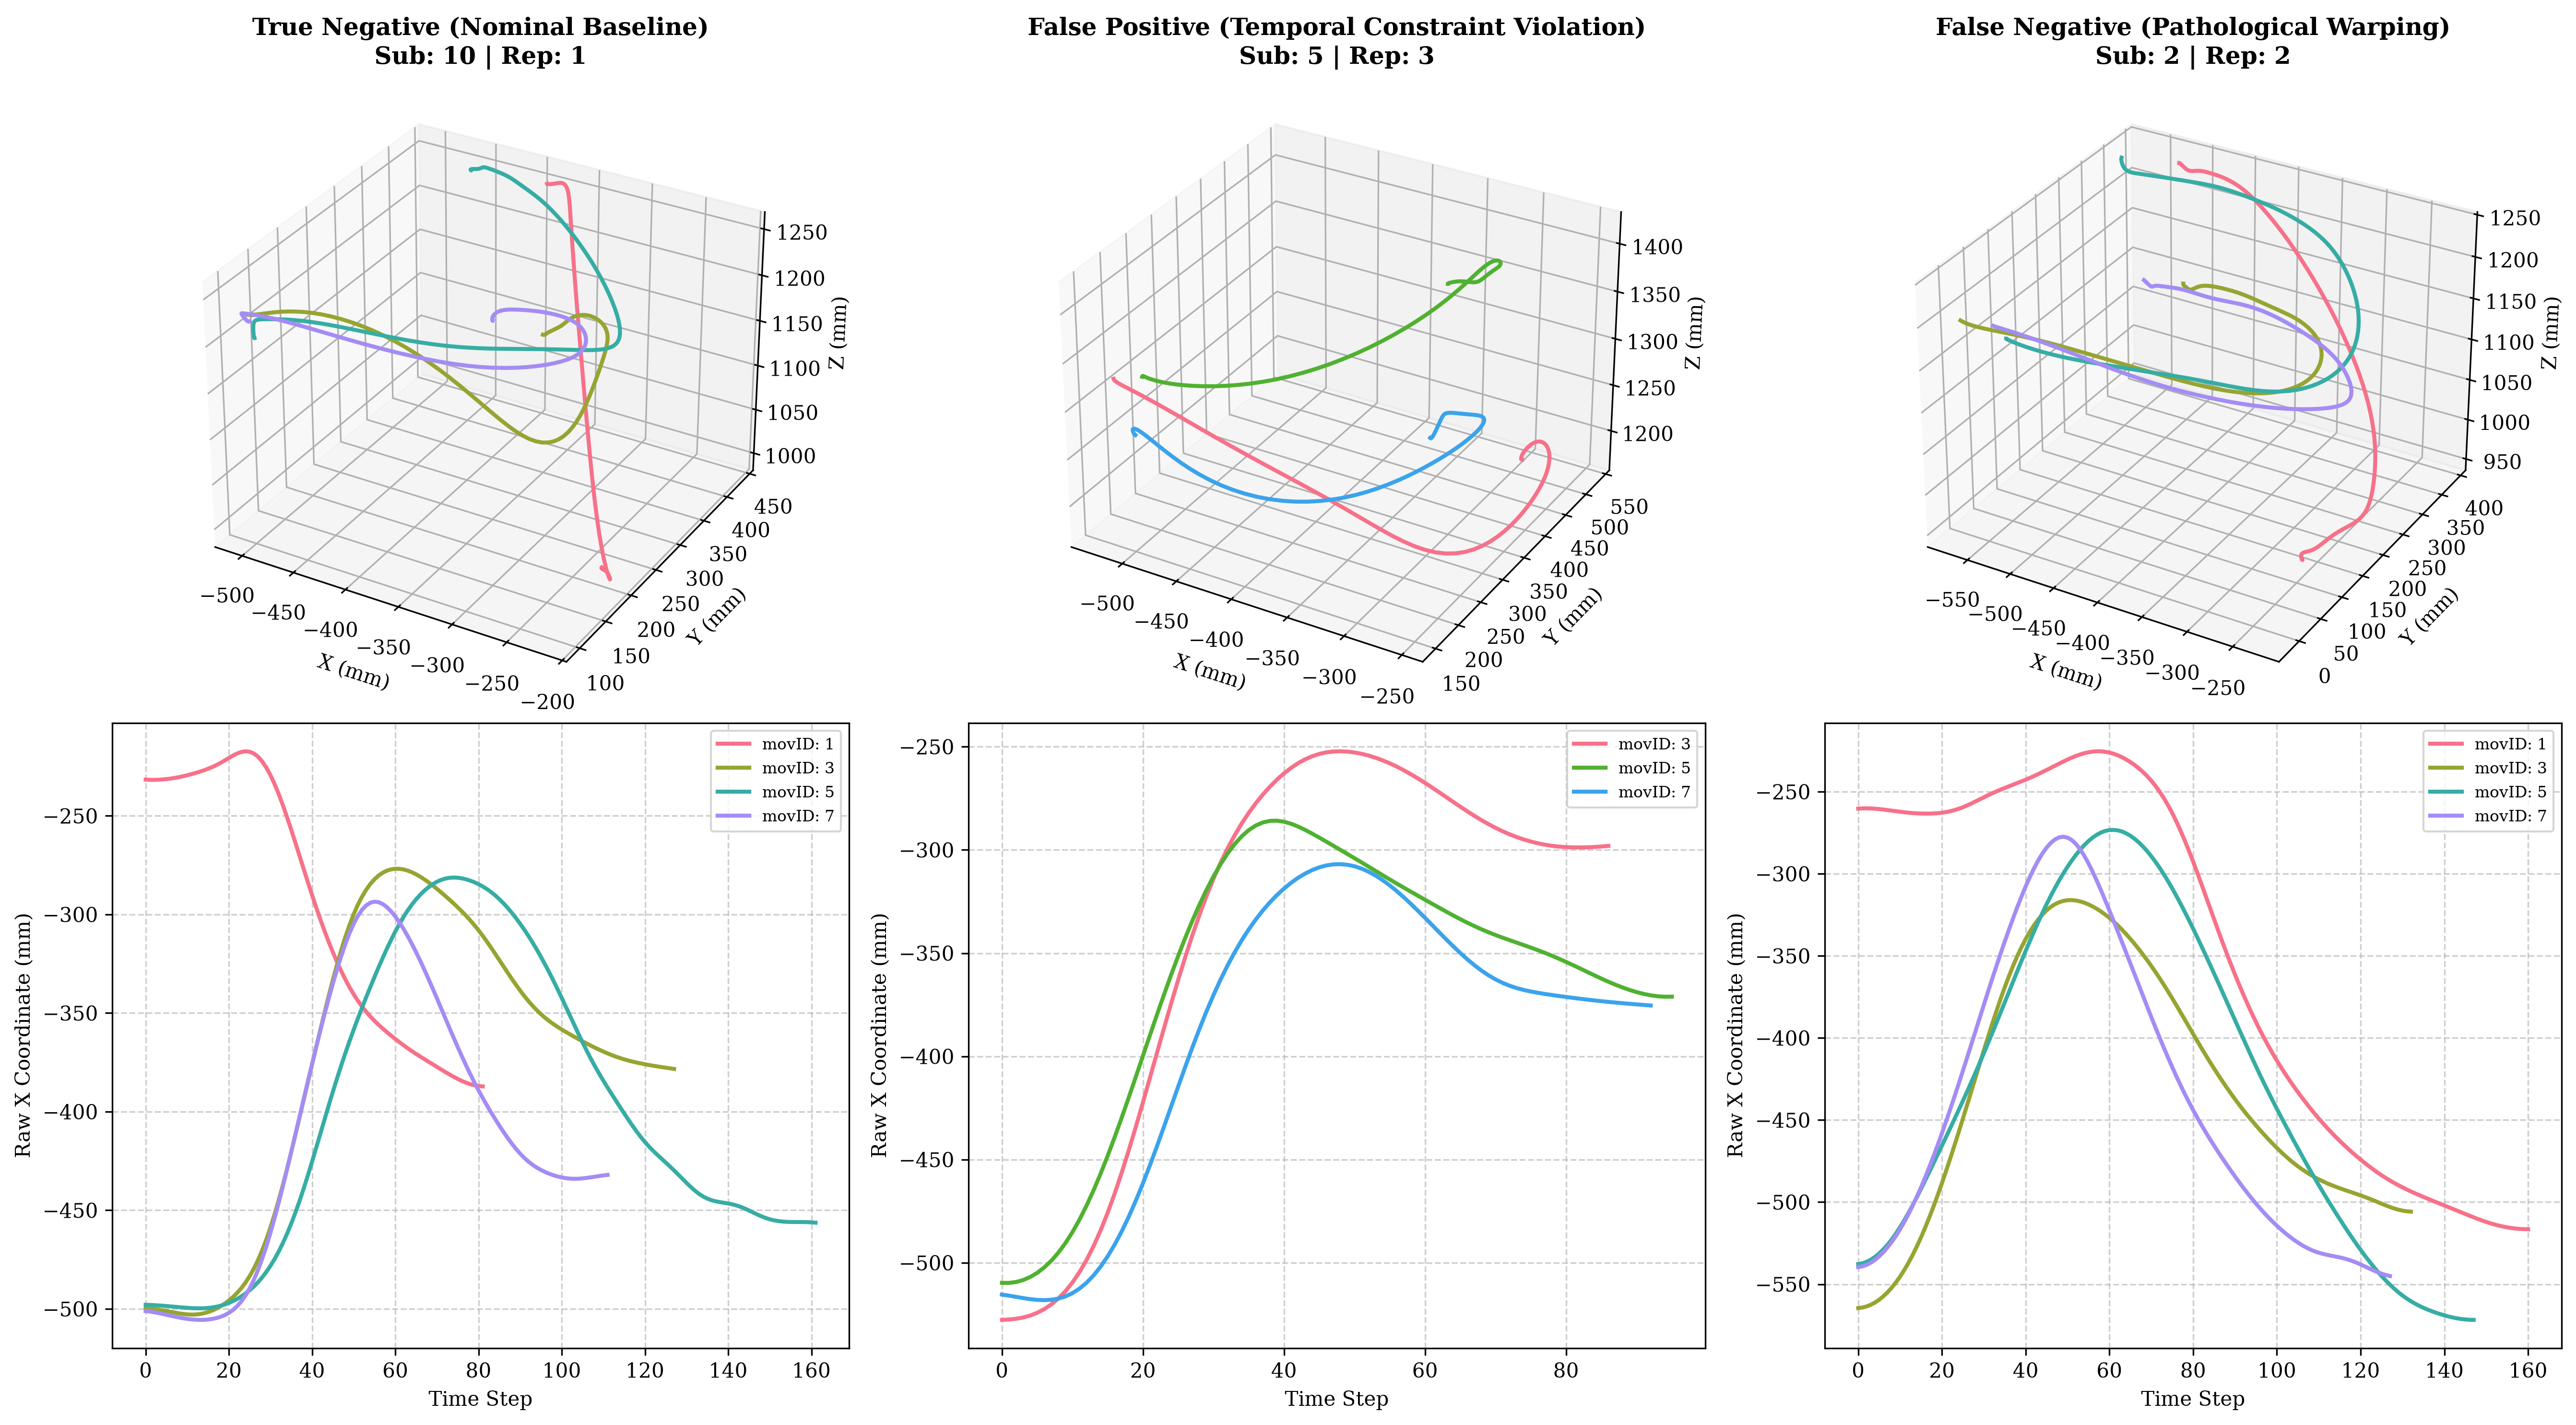

In [17]:
def plot_dtw_analysis(tn_df, fp_df, fn_df):
    plt.rcParams.update({'font.size': 10, 'font.family': 'serif'})
    fig = plt.figure(figsize=(18, 10), dpi=300)

    # [(dataframe, subplot_index, title), ...]
    datasets = [
        (tn_df, 1, 'True Negative (Nominal Baseline)'),
        (fp_df, 2, 'False Positive (Temporal Constraint Violation)'),
        (fn_df, 3, 'False Negative (Pathological Warping)')
    ]
    
    for data, col_idx, title in datasets:
        if data.empty:
            continue
            
        sub_id = data['sub'].iloc[0]
        rep_id = data['repID'].iloc[0]
        unique_movs = data['movID'].unique()
        colors = sns.color_palette("husl", len(unique_movs))
        
        ax3d = fig.add_subplot(2, 3, col_idx, projection='3d')
        for mov_id, color in zip(unique_movs, colors):
            subset = data[data['movID'] == mov_id]
            ax3d.plot(subset['x'], subset['y'], subset['z'], color=color, linewidth=2)
        
        ax3d.set_title(f"{title}\nSub: {sub_id} | Rep: {rep_id}", fontweight='bold')
        ax3d.set_xlabel('X (mm)')
        ax3d.set_ylabel('Y (mm)')
        ax3d.set_zlabel('Z (mm)')
        
        ax_x = fig.add_subplot(2, 3, col_idx + 3)
        for mov_id, color in zip(unique_movs, colors):
            subset = data[data['movID'] == mov_id]
            ax_x.plot(range(len(subset)), subset['x'], color=color, linewidth=2, label=f'movID: {mov_id}')
            
        ax_x.set_xlabel('Time Step')
        ax_x.set_ylabel('Raw X Coordinate (mm)')
        ax_x.grid(True, linestyle='--', alpha=0.6)
        ax_x.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

plot_dtw_analysis(tn_dtw_data, fp_dtw_data, fn_dtw_data)